<a href="https://colab.research.google.com/github/zeer055-a11y/rl-pid-finalcode/blob/main/RL_PID_%EC%84%B8%EC%A0%9C%EC%96%B4%EA%B8%B0%EB%B9%84%EA%B5%90.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/zeer055-a11y/rl-pid-finalcode/blob/main/RL_PID_%EC%99%B8%EB%9E%80%EC%A0%9C%EA%B1%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 강화학습을 활용한 Cart-pole PID 게인 자동 튜닝

이 노트북은 PPO가 제어입력을 직접 생성하지 않고, 내부 각도 PID 제어기의 게인 `Kp`, `Ki`, `Kd`를 조정하도록 구성되어 있습니다. 외부 위치 PD 루프가 목표 막대 각도를 만들고, curriculum 방식으로 외란 난이도를 높이며 학습한 뒤 고정 PID와 RL-PID의 성능을 비교합니다.

보상은 평가 지표인 실제 각도와 위치 오차를 중심으로 설계했습니다. 게인 범위와 학습량을 늘렸으며, 동일한 초기조건·외란 시드의 30개 평가 에피소드에서 고정 PID와 비교합니다. PPO의 우세는 실행 결과로 판단해야 합니다. 아래 셀을 위에서부터 순서대로 실행하세요.

## 수정: 외란을 관측하지 않는 RL-PID

PPO의 actor와 critic은 동일한 **9차원 관측값**만 받습니다. 외란의 실제값, 종류, 크기, 주파수, 발생 시점, 난이도는 정책 입력에 포함되지 않습니다.

관측값의 순서는 다음과 같습니다. 모든 항목은 기존 스케일로 정규화하고 [-5, 5]로 제한합니다.

| 인덱스 | 관측값 | 정규화 |
|---|---|---|
| 0 | 카트 위치 x | x / X_LIMIT |
| 1 | 카트 속도 x_dot | x_dot / X_DOT_SCALE |
| 2 | 각도 오차 e_theta = theta - theta_ref | e_theta / THETA_LIMIT |
| 3 | 막대 각속도 theta_dot | theta_dot / THETA_DOT_SCALE |
| 4 | PID 내부 적분 상태 | integral / 3 |
| 5–7 | 현재 Kp, Ki, Kd | (gains - NOMINAL_GAINS) / GAIN_SPAN |
| 8 | 직전 제어 명령 u (외란이 더해지기 전) | prev_u / u_limit |

외란은 시뮬레이터의 운동방정식에만 가해지며, PPO는 그 결과로 변한 상태/오차를 관측하여 게인을 조절합니다. 외란 로그는 사후 그래프용입니다. `info`의 난이도는 진단 메타데이터이며 현재 MlpPolicy 입력으로 전달되지 않습니다. 보상은 상태 오차와 제어입력, 게인 변화로 계산하며 외란값을 직접 사용하지 않습니다.

기존 보상, 게인 범위, 제어 주기(0.02 s), 게인 갱신 주기(0.1 s), 외란 curriculum, 동일 시드 비교를 유지했습니다. 현재 상태 관측 방식이며 별도 외란 추정기나 관측 이력 스택은 추가하지 않았습니다. 상태/속도는 기존과 같이 시뮬레이터에서 얻는 이상적인 측정값입니다.

**반드시 처음부터 재학습하세요.** 기존 10차원 정책과 호환되지 않습니다. 각 실행은 별도 모델 폴더를 사용하며, 기존 출력은 삭제했습니다. 기본값은 500,000 step 학습입니다. `SMOKE_TEST=True`는 실행 확인용이며 성능 비교 결론에 쓰지 마세요. 외란 정보를 제거한 이후의 성능 향상 여부는 새 학습 결과로 판단해야 합니다.


## 0. 패키지 설치

실행에 필요한 Gymnasium과 Stable-Baselines3를 설치하고, 그래프에서 한글이 깨지지 않도록 나눔 글꼴을 설치합니다. Colab 런타임에서는 가장 먼저 이 셀을 실행합니다.

In [ ]:
# ============================================================
# 0. 패키지 설치
# ============================================================
!pip install -q "gymnasium>=0.29" "stable-baselines3>=2.3"

# 한글 폰트
!apt-get -qq update
!apt-get -qq install -y fonts-nanum



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 5.0 MB/s eta 0:00:00
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fonts-nanum.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...


## 1. 라이브러리 불러오기 및 시드 설정

수치 계산, 데이터 처리, 시각화, 강화학습 환경 구성에 필요한 라이브러리를 불러옵니다. 난수 시드를 고정하여 가능한 범위에서 실험 재현성을 확보하고, Matplotlib의 한글 표시 설정도 적용합니다.

In [ ]:
# ============================================================
# 1. Import
# ============================================================
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from dataclasses import dataclass
from typing import Optional

import gymnasium as gym
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env

import torch

from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import (
    BaseCallback,
    EvalCallback,
    CallbackList,
)

plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)



## 2. Cart-pole 동역학

Cart-pole의 물리 파라미터와 상태 미분식을 정의하고, 4차 Runge–Kutta 방법으로 상태를 적분합니다. 마지막의 간단한 단언문은 힘과 각가속도의 부호 관계가 의도한 동역학과 일치하는지 확인합니다.

In [ ]:
# ============================================================
# 2. Cart-pole 동역학
# ============================================================
@dataclass
class CartPoleParams:
    M: float = 1.0
    m: float = 0.1
    l: float = 0.5
    g: float = 9.8
    dt: float = 0.02


def state_derivative(state, u, disturbance, p):
    x, x_dot, theta, theta_dot = state

    total_force = u + disturbance
    sin_t = np.sin(theta)
    cos_t = np.cos(theta)
    total_mass = p.M + p.m

    denominator = p.l * (
        4.0 / 3.0
        - p.m * cos_t**2 / total_mass
    )

    theta_ddot = (
        p.g * sin_t
        - cos_t
        * (
            total_force
            + p.m * p.l * theta_dot**2 * sin_t
        )
        / total_mass
    ) / denominator

    x_ddot = (
        total_force
        + p.m
        * p.l
        * (
            theta_dot**2 * sin_t
            - theta_ddot * cos_t
        )
    ) / total_mass

    return np.array(
        [x_dot, x_ddot, theta_dot, theta_ddot],
        dtype=np.float64,
    )


def rk4_step(state, u, disturbance, p):
    dt = p.dt

    k1 = state_derivative(state, u, disturbance, p)
    k2 = state_derivative(
        state + 0.5 * dt * k1,
        u,
        disturbance,
        p,
    )
    k3 = state_derivative(
        state + 0.5 * dt * k2,
        u,
        disturbance,
        p,
    )
    k4 = state_derivative(
        state + dt * k3,
        u,
        disturbance,
        p,
    )

    next_state = state + (
        dt / 6.0
    ) * (k1 + 2 * k2 + 2 * k3 + k4)

    if not np.all(np.isfinite(next_state)):
        raise FloatingPointError("상태에 NaN 또는 Inf 발생")

    return next_state


# 부호 검증
test_state = np.array([
    0.0,
    0.0,
    np.deg2rad(2.0),
    0.0,
])

d0 = state_derivative(
    test_state,
    u=0.0,
    disturbance=0.0,
    p=CartPoleParams(),
)

d1 = state_derivative(
    test_state,
    u=1.0,
    disturbance=0.0,
    p=CartPoleParams(),
)

assert d0[3] > 0
assert d1[3] < d0[3]

print("동역학 부호 검증 통과")



동역학 부호 검증 통과


## 3. 내부 각도 PID 제어기

막대 각도를 안정화하는 내부 PID 제어기를 정의합니다. 적분 포화, 미분항 저역통과 필터, 제어입력 포화 및 clamping 방식의 anti-windup이 포함됩니다.

In [ ]:
# ============================================================
# 3. 내부 각도 PID
# ============================================================
@dataclass
class PIDConfig:
    dt: float = 0.02
    u_limit: float = 15.0
    integral_limit: float = 3.0
    derivative_alpha: float = 0.3


class AnglePID:
    def __init__(self, cfg):
        self.cfg = cfg
        self.reset()

    def reset(self):
        self.integral = 0.0
        self.prev_error = 0.0
        self.filtered_derivative = 0.0
        self.has_prev_error = False

    def compute(self, kp, ki, kd, error):
        dt = self.cfg.dt

        # 적분
        integral_candidate = self.integral + error * dt
        integral_candidate = np.clip(
            integral_candidate,
            -self.cfg.integral_limit,
            self.cfg.integral_limit,
        )

        # 미분
        if self.has_prev_error:
            raw_derivative = (
                error - self.prev_error
            ) / dt
        else:
            raw_derivative = 0.0

        alpha = self.cfg.derivative_alpha

        self.filtered_derivative = (
            alpha * raw_derivative
            + (1.0 - alpha)
            * self.filtered_derivative
        )

        u_unsat = (
            kp * error
            + ki * integral_candidate
            + kd * self.filtered_derivative
        )

        u = float(np.clip(
            u_unsat,
            -self.cfg.u_limit,
            self.cfg.u_limit,
        ))

        # Clamping anti-windup
        if abs(u_unsat) < self.cfg.u_limit:
            self.integral = float(integral_candidate)

        self.prev_error = float(error)
        self.has_prev_error = True

        return u




## 4. 외부 위치 PD 제어기

카트의 위치와 속도 오차로부터 목표 막대 각도 `theta_ref`를 생성하는 외부 PD 루프를 정의합니다. 생성된 목표 각도는 설정된 최대 범위 안으로 제한됩니다.

In [ ]:
# ============================================================
# 4. 외부 위치 PD
# ============================================================
@dataclass
class OuterPositionPD:
    kpx: float = 0.1
    kdx: float = 0.1
    theta_ref_max: float = np.deg2rad(10.0)

    def compute(self, x, x_dot, x_ref=0.0):
        theta_ref = (
            self.kpx * (x_ref - x)
            - self.kdx * x_dot
        )

        return float(np.clip(
            theta_ref,
            -self.theta_ref_max,
            self.theta_ref_max,
        ))




## 5. 환경 및 게인 설정

고정 PID의 기준 게인은 그대로 둔 채 PPO의 게인 조정 범위를 확대합니다. 학습 보상은 평가 지표의 실제 각도·위치 오차를 중심으로 구성하고, 종료 직전에도 비용 차이가 학습 신호로 남도록 클리핑을 제거했습니다. 보상 계수는 가설에 따른 설정값이며 결과를 보장하지 않습니다.


In [ ]:
# ============================================================
# 5. 환경 및 게인 설정
# ============================================================
PHYS_DT = 0.02
GAIN_UPDATE_EVERY = 5
EPISODE_LENGTH = 8.0

MAX_PHYS_STEPS = int(
    EPISODE_LENGTH / PHYS_DT
)

MAX_RL_STEPS = (
    MAX_PHYS_STEPS // GAIN_UPDATE_EVERY
)

X_LIMIT = 2.4
THETA_LIMIT = np.deg2rad(25.0)

X_DOT_SCALE = 3.0
THETA_DOT_SCALE = 5.0

# 안정한 기준 게인
NOMINAL_GAINS = np.array([
    20.0,
    0.0,
    4.0,
])

# PPO가 조정할 수 있는 범위
GAIN_SPAN = np.array([
    16.0,
    1.5,
    3.0,
])

GAIN_MIN = np.array([
    4.0,
    0.0,
    1.0,
])

GAIN_MAX = np.array([
    36.0,
    1.5,
    7.0,
])

GAIN_SMOOTHING = 0.45

# 평가 지표(theta, x)와 같은 상태 오차를 중심으로 학습한다.
# 각도 추종 오차는 내부 PID의 역할을 학습하기 위한 보조항이다.
R_THETA = np.deg2rad(8.0)
R_X = 0.45
R_E_THETA = np.deg2rad(10.0)
R_THETA_DOT = 2.0
R_X_DOT = 1.5

W_THETA = 1.2
W_X = 1.8
W_E_THETA = 0.25
W_THETA_DOT = 0.08
W_X_DOT = 0.10
W_U = 0.005
W_DU = 0.002
W_GAIN_RATE = 0.002

TERMINATION_PENALTY = 25.0
SUCCESS_BONUS = 0.0


def action_to_gains(current_gains, action):
    action = np.clip(
        np.asarray(action, dtype=np.float64),
        -1.0,
        1.0,
    )

    target_gains = (
        NOMINAL_GAINS
        + action * GAIN_SPAN
    )

    target_gains = np.clip(
        target_gains,
        GAIN_MIN,
        GAIN_MAX,
    )

    new_gains = current_gains + (
        GAIN_SMOOTHING
        * (target_gains - current_gains)
    )

    normalized_rate = (
        new_gains - current_gains
    ) / GAIN_SPAN

    return new_gains, normalized_rate


OBSERVATION_NAMES = (
    "x", "x_dot", "e_theta", "theta_dot", "integral",
    "kp_normalized", "ki_normalized", "kd_normalized", "prev_u",
)
OBS_DIM = len(OBSERVATION_NAMES)


def build_observation(
    x,
    x_dot,
    e_theta,
    theta_dot,
    integral,
    gains,
    prev_u,
    u_limit,
):
    normalized_gains = (
        gains - NOMINAL_GAINS
    ) / GAIN_SPAN

    obs = np.array([
        x / X_LIMIT,
        x_dot / X_DOT_SCALE,
        e_theta / THETA_LIMIT,
        theta_dot / THETA_DOT_SCALE,
        integral / 3.0,
        normalized_gains[0],
        normalized_gains[1],
        normalized_gains[2],
        prev_u / u_limit,
    ], dtype=np.float32)

    return np.clip(obs, -5.0, 5.0)


def physics_reward(
    x,
    x_dot,
    theta,
    e_theta,
    theta_dot,
    u,
    prev_u,
    u_limit,
):
    # 실제 theta와 x는 평가 RMSE에 직접 대응한다.
    # 비용을 자르지 않아 실패에 접근할 때에도 기울기가 남는다.
    cost = (
        W_THETA * (theta / R_THETA) ** 2
        + W_X * (x / R_X) ** 2
        + W_E_THETA * (e_theta / R_E_THETA) ** 2
        + W_THETA_DOT * (theta_dot / R_THETA_DOT) ** 2
        + W_X_DOT * (x_dot / R_X_DOT) ** 2
        + W_U * (u / u_limit) ** 2
        + W_DU * ((u - prev_u) / (2.0 * u_limit)) ** 2
    )
    return float(1.0 - cost)


## 6. Curriculum 외란 생성기

학습 난이도에 따라 외란의 크기와 특성이 달라지는 생성기를 정의합니다. 에피소드마다 무외란, 펄스, 정현파, 랜덤 외란 중 하나를 선택하고 현재 시각의 외란 값을 계산합니다.

In [ ]:
# ============================================================
# 6. Curriculum 외란 생성기
# ============================================================
def sample_disturbance_config(
    rng,
    difficulty,
    episode_length,
):
    """
    difficulty:
        0 = 약한 외란
        1 = 최대 학습 외란
    """

    difficulty = float(np.clip(
        difficulty,
        0.0,
        1.0,
    ))

    kind = rng.choice(
        ["none", "pulse", "sine", "random"],
        p=[0.15, 0.50, 0.25, 0.10],
    )

    config = {"kind": kind}

    if kind == "pulse":
        magnitude_max = (
            0.5 + 3.5 * difficulty
        )

        config["magnitude"] = rng.uniform(
            0.3,
            magnitude_max,
        ) * rng.choice([-1.0, 1.0])

        config["start_time"] = rng.uniform(
            1.0,
            3.0,
        )

        config["duration"] = rng.uniform(
            0.3,
            1.2,
        )

    elif kind == "sine":
        config["amplitude"] = rng.uniform(
            0.2,
            0.5 + 2.0 * difficulty,
        )

        config["frequency"] = rng.uniform(
            0.2,
            0.5 + difficulty,
        )

        config["start_time"] = rng.uniform(
            1.0,
            2.0,
        )

        config["duration"] = rng.uniform(
            1.0,
            3.0,
        )

        config["phase"] = rng.uniform(
            0.0,
            2.0 * np.pi,
        )

    elif kind == "random":
        config["amplitude"] = (
            0.2 + 1.0 * difficulty
        )

    return config


def disturbance_at(config, time, rng):
    kind = config["kind"]

    if kind == "none":
        return 0.0

    if kind == "pulse":
        start = config["start_time"]
        end = start + config["duration"]

        if start <= time < end:
            return config["magnitude"]

        return 0.0

    if kind == "sine":
        start = config["start_time"]
        end = start + config["duration"]

        if not start <= time < end:
            return 0.0

        tau = time - start

        return (
            config["amplitude"]
            * np.sin(
                2.0
                * np.pi
                * config["frequency"]
                * tau
                + config["phase"]
            )
        )

    if kind == "random":
        return float(rng.uniform(
            -config["amplitude"],
            config["amplitude"],
        ))

    raise ValueError(kind)




## 7. Gymnasium 강화학습 환경

PPO가 PID의 `Kp`, `Ki`, `Kd`를 조정할 수 있도록 Gymnasium 환경을 구성합니다. 한 번의 RL 스텝 동안 여러 물리 스텝을 실행하며, 종료 조건·보상·관측·게인 갱신을 처리합니다. 마지막에는 Gymnasium 환경 규격을 검사합니다.

In [ ]:
# ============================================================
# 7. Gymnasium 환경
# ============================================================
class RLPIDCartPoleEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, seed=None):
        super().__init__()

        self.params = CartPoleParams(dt=PHYS_DT)
        self.outer_pd = OuterPositionPD()

        self.pid_cfg = PIDConfig(
            dt=PHYS_DT,
            u_limit=15.0,
            integral_limit=3.0,
            derivative_alpha=0.3,
        )

        self.pid = AnglePID(self.pid_cfg)

        self.observation_space = spaces.Box(
            low=-5.0,
            high=5.0,
            shape=(OBS_DIM,),
            dtype=np.float32,
        )

        self.action_space = spaces.Box(
            low=-1.0,
            high=1.0,
            shape=(3,),
            dtype=np.float32,
        )

        self.rng = np.random.default_rng(seed)
        self.difficulty = 0.15

    def set_difficulty(self, difficulty):
        self.difficulty = float(np.clip(
            difficulty,
            0.0,
            1.0,
        ))

    def reset(
        self,
        *,
        seed=None,
        options=None,
    ):
        super().reset(seed=seed)

        if seed is not None:
            self.rng = np.random.default_rng(seed)

        self.state = np.array([
            self.rng.uniform(-0.15, 0.15),
            self.rng.uniform(-0.08, 0.08),
            self.rng.uniform(
                np.deg2rad(-4.0),
                np.deg2rad(4.0),
            ),
            self.rng.uniform(-0.08, 0.08),
        ], dtype=np.float64)

        self.gains = NOMINAL_GAINS.copy()

        self.pid.reset()

        self.prev_u = 0.0
        self.current_disturbance = 0.0
        self.time = 0.0
        self.phys_step = 0

        self.dist_config = (
            sample_disturbance_config(
                self.rng,
                self.difficulty,
                EPISODE_LENGTH,
            )
        )

        self.dist_rng = np.random.default_rng(
            int(self.rng.integers(
                0,
                1_000_000,
            ))
        )

        return self._get_obs(), {}

    def _get_obs(self):
        # 정책 입력에는 외란값/종류/시점/난이도를 포함하지 않는다.
        x, x_dot, theta, theta_dot = self.state

        theta_ref = self.outer_pd.compute(
            x,
            x_dot,
        )

        # 현재 동역학 부호에 맞춘 오차
        e_theta = theta - theta_ref

        return build_observation(
            x=x,
            x_dot=x_dot,
            e_theta=e_theta,
            theta_dot=theta_dot,
            integral=self.pid.integral,
            gains=self.gains,
            prev_u=self.prev_u,
            u_limit=self.pid_cfg.u_limit,
        )

    def step(self, action):
        old_gains = self.gains.copy()

        self.gains, gain_rate = (
            action_to_gains(
                self.gains,
                action,
            )
        )

        reward_sum = 0.0
        executed_steps = 0
        terminated = False

        for _ in range(GAIN_UPDATE_EVERY):
            x, x_dot, theta, theta_dot = (
                self.state
            )

            theta_ref = self.outer_pd.compute(
                x,
                x_dot,
            )

            e_theta = theta - theta_ref

            u = self.pid.compute(
                kp=self.gains[0],
                ki=self.gains[1],
                kd=self.gains[2],
                error=e_theta,
            )

            self.current_disturbance = (
                disturbance_at(
                    self.dist_config,
                    self.time,
                    self.dist_rng,
                )
            )

            try:
                self.state = rk4_step(
                    self.state,
                    u,
                    self.current_disturbance,
                    self.params,
                )
            except FloatingPointError:
                terminated = True
                break

            self.time += PHYS_DT
            self.phys_step += 1
            executed_steps += 1

            (
                x_new,
                x_dot_new,
                theta_new,
                theta_dot_new,
            ) = self.state

            theta_ref_new = (
                self.outer_pd.compute(
                    x_new,
                    x_dot_new,
                )
            )

            e_theta_new = (
                theta_new - theta_ref_new
            )

            reward_sum += physics_reward(
                x=x_new,
                x_dot=x_dot_new,
                theta=theta_new,
                e_theta=e_theta_new,
                theta_dot=theta_dot_new,
                u=u,
                prev_u=self.prev_u,
                u_limit=self.pid_cfg.u_limit,
            )

            self.prev_u = u

            if (
                abs(x_new) > X_LIMIT
                or abs(theta_new) > THETA_LIMIT
            ):
                terminated = True
                break

        reward = (
            reward_sum
            / max(executed_steps, 1)
        )

        reward -= (
            W_GAIN_RATE
            * np.sum(gain_rate**2)
        )

        if terminated:
            reward -= TERMINATION_PENALTY

        truncated = (
            not terminated
            and self.phys_step
            >= MAX_PHYS_STEPS
        )

        if truncated:
            reward += SUCCESS_BONUS

        info = {
            "gains": self.gains.copy(),
            "is_success": bool(truncated),
            "difficulty": self.difficulty,
        }

        return (
            self._get_obs(),
            float(reward),
            terminated,
            truncated,
            info,
        )


test_env = RLPIDCartPoleEnv(seed=SEED)
check_env(test_env, skip_render_check=True)

print("Gymnasium 환경 검증 통과")



Gymnasium 환경 검증 통과


In [ ]:
# 외란 메타데이터가 관측에 직접 유입되지 않는지 검사
probe = RLPIDCartPoleEnv(seed=SEED)
obs_before, _ = probe.reset(seed=SEED)
assert obs_before.shape == (9,)
assert probe.observation_space.contains(obs_before)
probe.current_disturbance = 12345.0
probe.dist_config = {"kind": "pulse", "magnitude": 999.0,
                     "start_time": 0.0, "duration": 100.0}
probe.set_difficulty(1.0)
# 같은 측정 상태/제어기 상태이면 숨겨진 외란 정보와 무관하게 같은 관측.
np.testing.assert_array_equal(obs_before, probe._get_obs())

# 외란 자체는 제거되지 않았는지: 동일 초기 상태에 다른 외란을 가하면 반응이 다름.
quiet = RLPIDCartPoleEnv(seed=SEED)
forced = RLPIDCartPoleEnv(seed=SEED)
quiet.reset(seed=SEED)
forced.reset(seed=SEED)
quiet.dist_config = {"kind": "none"}
forced.dist_config = {"kind": "pulse", "magnitude": 2.0,
                      "start_time": 0.0, "duration": EPISODE_LENGTH}
zero_action = np.zeros(3, dtype=np.float32)
quiet_obs, *_ = quiet.step(zero_action)
forced_obs, *_ = forced.step(zero_action)
assert not np.allclose(quiet.state, forced.state)
assert not np.allclose(quiet_obs, forced_obs)
for item in (probe, quiet, forced):
    item.close()
print("검증 통과: 외란 직접 관측 없음 / 외란에 의한 상태 변화는 관측 가능")


검증 통과: 외란 직접 관측 없음 / 외란에 의한 상태 변화는 관측 가능


## 8. Curriculum callback

학습 진행률이 높아질수록 외란 난이도를 `0.15`에서 `1.0`까지 점진적으로 증가시키는 콜백을 정의합니다. 벡터화된 모든 학습 환경에 동일한 난이도를 전달합니다.

In [ ]:
# ============================================================
# 8. Curriculum callback
# ============================================================
class CurriculumCallback(BaseCallback):
    def __init__(self, total_timesteps):
        super().__init__()
        self.total_timesteps_target = (
            total_timesteps
        )

    def _on_step(self):
        progress = min(
            self.num_timesteps
            / self.total_timesteps_target,
            1.0,
        )

        # 처음부터 외란 0으로 시작하지 않고
        # 0.15 → 1.0으로 점진적으로 증가
        difficulty = 0.15 + 0.85 * progress

        self.training_env.env_method(
            "set_difficulty",
            difficulty,
        )

        return True




## 9. PPO 학습

병렬 학습 환경과 별도 평가 환경을 만들고 PPO 모델 및 콜백을 설정합니다. 학습 중 최고 성능 모델을 저장하며, 학습 완료 후 최고 모델이 있으면 이를 불러오고 그렇지 않으면 최종 모델을 사용합니다.

In [ ]:
# ============================================================
# 9. PPO 학습
# ============================================================
# 저장된 모델(zip)이 있으면 학습을 건너뛰고 불러온다. 없으면 기존처럼 새로 학습한다.
# 같은 시드(42)로 학습하면 같은 모델이 나오므로, 결과를 다시 뽑을 때 학습 시간을 줄이는 용도다.
PRETRAINED_PATH = "rlpid_best_model.zip"

if PRETRAINED_PATH and os.path.exists(PRETRAINED_PATH):
    trained_model = PPO.load(PRETRAINED_PATH, device="cpu")
    print("저장된 모델을 불러왔습니다:", PRETRAINED_PATH)
else:
    SMOKE_TEST = False
    N_ENVS = 4

    TOTAL_TIMESTEPS = (
        4_096
        if SMOKE_TEST
        else 500_000
    )

    train_env = make_vec_env(
        RLPIDCartPoleEnv,
        n_envs=N_ENVS,
        seed=SEED,
    )

    eval_env = Monitor(
        RLPIDCartPoleEnv(
            seed=SEED + 10_000,
        )
    )

    eval_env.unwrapped.set_difficulty(1.0)

    # 실행마다 별도 경로: 이전 10차원 모델 및 이전 실행의 best 모델 혼입 방지.
    from datetime import datetime
    RUN_ROOT = "/content" if os.path.isdir("/content") else "."
    RUN_DIR = os.path.join(
        RUN_ROOT, "rlpid_no_dist_obs_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    )
    BEST_MODEL_DIR = os.path.join(RUN_DIR, "best")

    os.makedirs(
        BEST_MODEL_DIR,
        exist_ok=True,
    )


    def learning_rate_schedule(
        progress_remaining,
    ):
        return 2e-4 * (0.2 + 0.8 * progress_remaining)


    model = PPO(
        policy="MlpPolicy",
        env=train_env,

        learning_rate=learning_rate_schedule,

        n_steps=1024,
        batch_size=256,
        n_epochs=10,

        gamma=0.999,
        gae_lambda=0.95,

        clip_range=0.2,

        # 불필요한 탐색을 계속 장려하지 않음
        ent_coef=0.0,

        vf_coef=0.5,
        max_grad_norm=0.5,

        policy_kwargs=dict(
            net_arch=dict(
                pi=[128, 128],
                vf=[128, 128],
            ),
            activation_fn=torch.nn.Tanh,

            # 기존 std=1보다 훨씬 작은 초기 탐색
            log_std_init=-1.2,
        ),

        seed=SEED,
        verbose=1,
        device="cpu",
    )

    curriculum_callback = CurriculumCallback(
        TOTAL_TIMESTEPS
    )

    eval_callback = EvalCallback(
        eval_env,

        best_model_save_path=BEST_MODEL_DIR,
        log_path=BEST_MODEL_DIR,

        eval_freq=max(
            20_000 // N_ENVS,
            1,
        ),

        # 기존 5회보다 신뢰도 향상
        n_eval_episodes=30,

        deterministic=True,
        verbose=1,
    )

    callbacks = CallbackList([
        curriculum_callback,
        eval_callback,
    ])

    model.learn(
        total_timesteps=TOTAL_TIMESTEPS,
        callback=callbacks,
        progress_bar=False,
    )

    FINAL_MODEL_PATH = os.path.join(RUN_DIR, "final_model")

    model.save(FINAL_MODEL_PATH)

    best_model_path = os.path.join(
        BEST_MODEL_DIR,
        "best_model.zip",
    )

    if os.path.exists(best_model_path):
        trained_model = PPO.load(
            best_model_path,
            device="cpu",
        )

        print(
            "가장 성능이 좋았던 모델을 불러왔습니다:",
            best_model_path,
        )
    else:
        trained_model = PPO.load(
            FINAL_MODEL_PATH,
            device="cpu",
        )

        print("최종 모델을 불러왔습니다.")
    print("모델 저장 폴더:", RUN_DIR)

assert trained_model.observation_space.shape == (OBS_DIM,)
print("학습 관측 항목:", OBSERVATION_NAMES)


저장된 모델을 불러왔습니다: rlpid_best_model.zip
학습 관측 항목: ('x', 'x_dot', 'e_theta', 'theta_dot', 'integral', 'kp_normalized', 'ki_normalized', 'kd_normalized', 'prev_u')


## 10. 고정 PID와 RL-PID 평가

동일한 외란 조건과 시드에서 고정 PID와 RL-PID를 각각 실행합니다. 각도·위치 RMSE, 누적 보상, 성공 여부, 생존시간을 계산하고 여러 평가 시드의 평균과 표준편차를 표로 요약합니다.

In [ ]:
# ============================================================
# 10. 고정 PID와 RL-PID 평가
# ============================================================
def run_episode(
    seed,
    use_rl,
    difficulty=1.0,
):
    env = RLPIDCartPoleEnv(seed=seed)
    env.set_difficulty(difficulty)

    obs, info = env.reset(seed=seed)

    log = {
        "time": [],
        "x": [],
        "theta": [],
        "u": [],
        "disturbance": [],
        "kp": [],
        "ki": [],
        "kd": [],
        "reward": [],
    }

    total_reward = 0.0

    while True:
        if use_rl:
            action, _ = trained_model.predict(
                obs,
                deterministic=True,
            )
        else:
            # action=0이면 nominal gain 유지
            action = np.zeros(
                3,
                dtype=np.float32,
            )

        obs, reward, terminated, truncated, info = (
            env.step(action)
        )

        total_reward += reward

        log["time"].append(env.time)
        log["x"].append(env.state[0])
        log["theta"].append(env.state[2])
        log["u"].append(env.prev_u)
        log["disturbance"].append(
            env.current_disturbance
        )
        log["kp"].append(env.gains[0])
        log["ki"].append(env.gains[1])
        log["kd"].append(env.gains[2])
        log["reward"].append(reward)

        if terminated or truncated:
            break

    for key in log:
        log[key] = np.asarray(log[key])

    log["success"] = bool(truncated)
    log["total_reward"] = total_reward
    log["elapsed_time"] = env.time

    return log


def compute_metrics(log):
    """
    실패한 에피소드의 남은 시간을 한계 상태로
    padding하여 조기 종료가 RMSE를 낮추는 문제를 방지한다.
    """
    n_total = MAX_RL_STEPS
    n_valid = len(log["theta"])
    n_missing = n_total - n_valid

    theta_sq_sum = np.sum(
        log["theta"]**2
    )

    x_sq_sum = np.sum(
        log["x"]**2
    )

    if n_missing > 0:
        theta_sq_sum += (
            n_missing * THETA_LIMIT**2
        )

        x_sq_sum += (
            n_missing * X_LIMIT**2
        )

    theta_rmse = np.sqrt(
        theta_sq_sum / n_total
    )

    x_rmse = np.sqrt(
        x_sq_sum / n_total
    )

    return {
        "각도 RMSE [deg]": np.rad2deg(
            theta_rmse
        ),
        "위치 RMSE [m]": x_rmse,
        "누적 reward": log["total_reward"],
        "성공": float(log["success"]),
        "생존시간 [s]": log["elapsed_time"],
    }


def evaluate_seeds(
    seeds,
    difficulty,
):
    fixed_rows = []
    rl_rows = []

    example = None

    for i, seed in enumerate(seeds):
        fixed_log = run_episode(
            seed=seed,
            use_rl=False,
            difficulty=difficulty,
        )

        rl_log = run_episode(
            seed=seed,
            use_rl=True,
            difficulty=difficulty,
        )

        fixed_rows.append(
            compute_metrics(fixed_log)
        )

        rl_rows.append(
            compute_metrics(rl_log)
        )

        if i == 0:
            example = {
                "fixed": fixed_log,
                "rl": rl_log,
            }

    return (
        pd.DataFrame(fixed_rows),
        pd.DataFrame(rl_rows),
        example,
    )


N_EVAL_SEEDS = 30
EVAL_SEEDS = list(range(
    20_000,
    20_000 + N_EVAL_SEEDS,
))

df_fixed, df_rl, example = evaluate_seeds(
    seeds=EVAL_SEEDS,
    difficulty=1.0,
)


def summarize(df, name):
    return pd.Series({
        "각도 RMSE [deg]":
            f"{df['각도 RMSE [deg]'].mean():.3f}"
            f" ± {df['각도 RMSE [deg]'].std():.3f}",

        "위치 RMSE [m]":
            f"{df['위치 RMSE [m]'].mean():.3f}"
            f" ± {df['위치 RMSE [m]'].std():.3f}",

        "누적 reward":
            f"{df['누적 reward'].mean():.3f}"
            f" ± {df['누적 reward'].std():.3f}",

        "성공률":
            f"{100 * df['성공'].mean():.1f}%",

        "평균 생존시간 [s]":
            f"{df['생존시간 [s]'].mean():.3f}",
    }, name=name)


summary = pd.DataFrame([
    summarize(
        df_fixed,
        "고정 PID",
    ),
    summarize(
        df_rl,
        "RL-PID",
    ),
])

display(summary)



,각도 RMSE [deg],위치 RMSE [m],누적 reward,성공률,평균 생존시간 [s]
고정 PID,4.409 ± 5.923,0.305 ± 0.579,28.862 ± 74.908,90.0%,7.460
RL-PID,2.114 ± 1.591,0.134 ± 0.144,40.577 ± 88.552,100.0%,8.000


## 11. 대표 결과 그래프

대표 평가 에피소드에 대해 카트 위치, 막대 각도, 제어입력과 외란, RL이 조정한 PID 게인, 누적 보상을 차례로 시각화하여 두 제어기의 응답을 비교합니다.

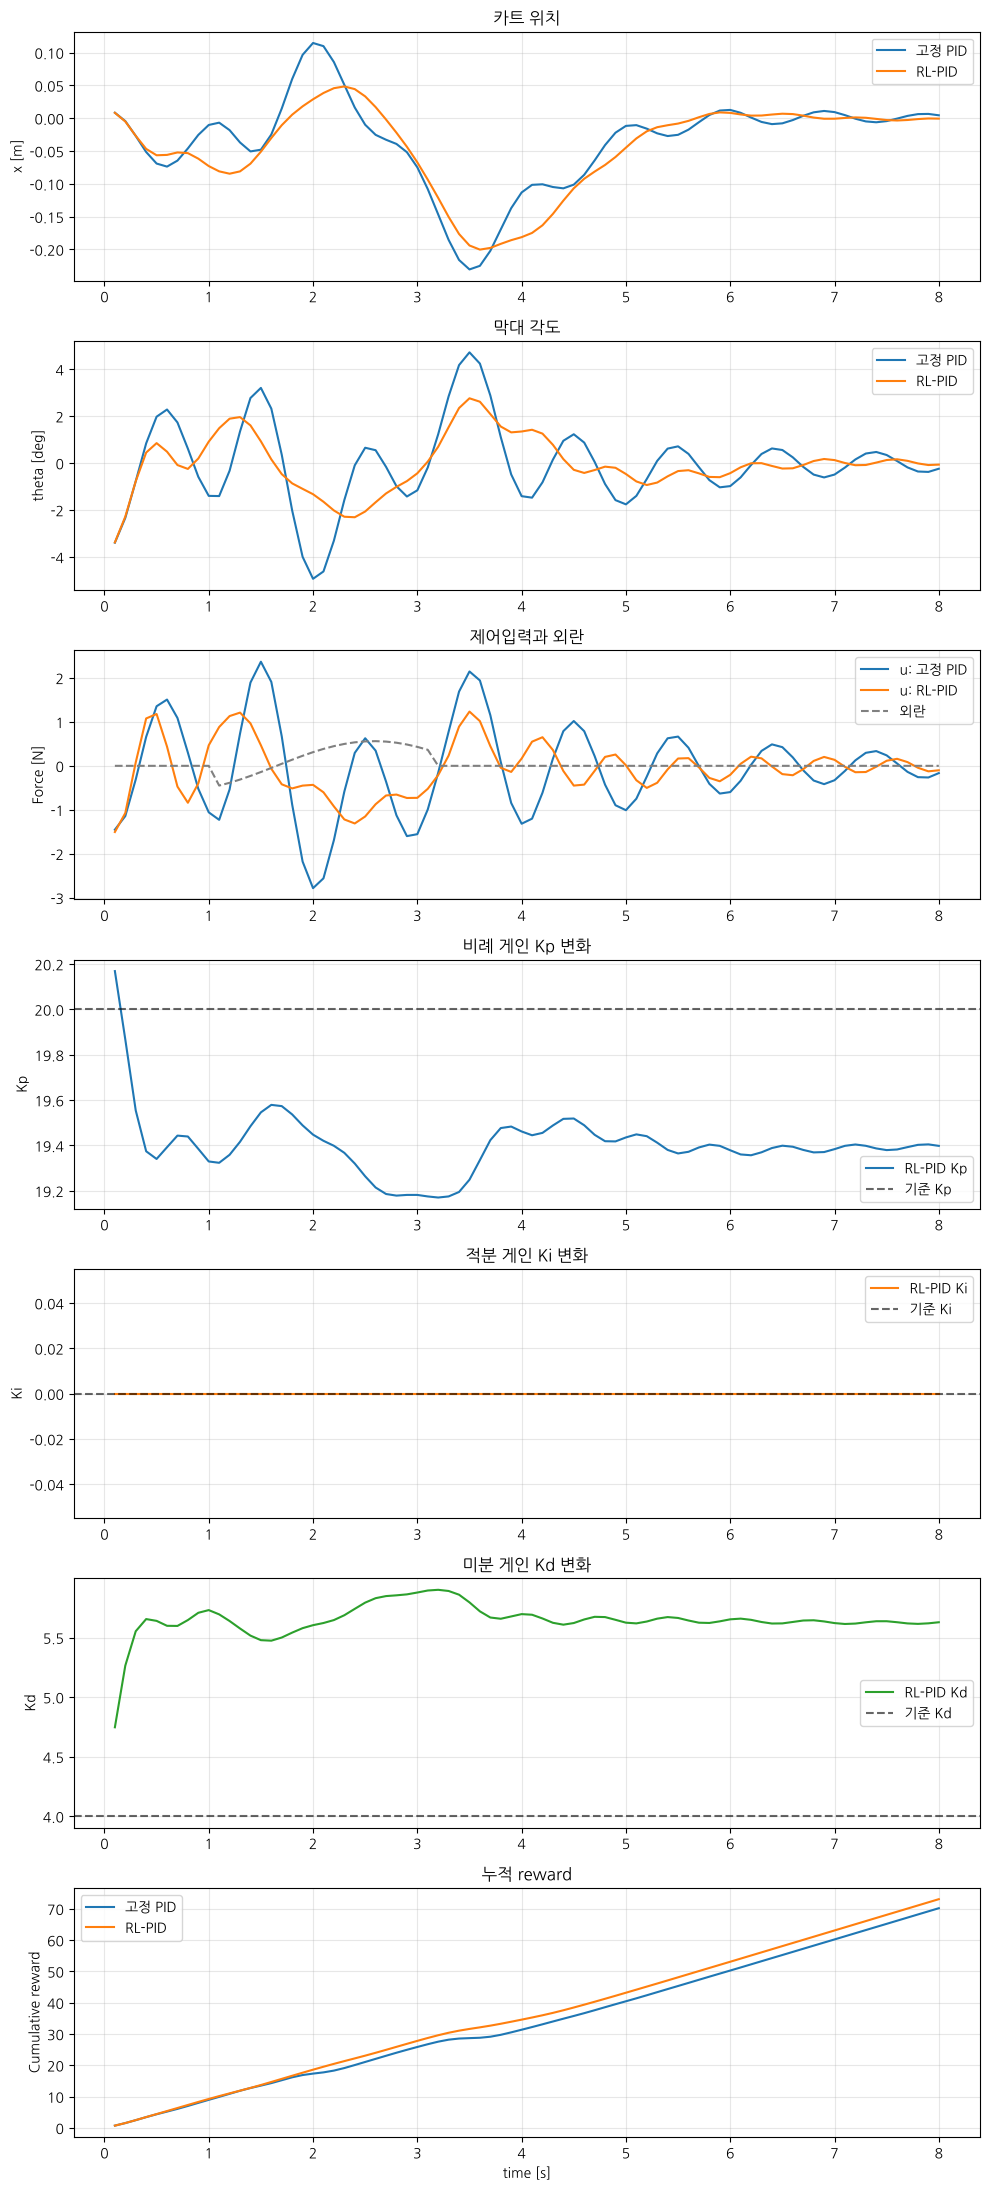

In [ ]:
# ============================================================
# 11. 대표 결과 그래프
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np

# Colab 한글 폰트 설정
font_path = (
    "/usr/share/fonts/truetype/nanum/"
    "NanumGothic.ttf"
)

fm.fontManager.addfont(font_path)
font_name = fm.FontProperties(
    fname=font_path
).get_name()

plt.rcParams["font.family"] = font_name
plt.rcParams["axes.unicode_minus"] = False

fixed = example["fixed"]
rl = example["rl"]

fig, axes = plt.subplots(
    7,
    1,
    figsize=(10, 22),
)

# 1. 카트 위치
axes[0].plot(
    fixed["time"],
    fixed["x"],
    label="고정 PID",
)

axes[0].plot(
    rl["time"],
    rl["x"],
    label="RL-PID",
)

axes[0].set_ylabel("x [m]")
axes[0].set_title("카트 위치")
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2. 막대 각도
axes[1].plot(
    fixed["time"],
    np.rad2deg(fixed["theta"]),
    label="고정 PID",
)

axes[1].plot(
    rl["time"],
    np.rad2deg(rl["theta"]),
    label="RL-PID",
)

axes[1].set_ylabel("theta [deg]")
axes[1].set_title("막대 각도")
axes[1].legend()
axes[1].grid(alpha=0.3)

# 3. 제어입력과 외란
axes[2].plot(
    fixed["time"],
    fixed["u"],
    label="u: 고정 PID",
)

axes[2].plot(
    rl["time"],
    rl["u"],
    label="u: RL-PID",
)

axes[2].plot(
    rl["time"],
    rl["disturbance"],
    "--",
    color="gray",
    label="외란",
)

axes[2].set_ylabel("Force [N]")
axes[2].set_title("제어입력과 외란")
axes[2].legend()
axes[2].grid(alpha=0.3)

# 4. 비례 게인 Kp
axes[3].plot(
    rl["time"],
    rl["kp"],
    color="tab:blue",
    label="RL-PID Kp",
)

axes[3].axhline(
    NOMINAL_GAINS[0],
    color="black",
    linestyle="--",
    alpha=0.6,
    label="기준 Kp",
)

axes[3].set_ylabel("Kp")
axes[3].set_title("비례 게인 Kp 변화")
axes[3].legend()
axes[3].grid(alpha=0.3)

# 5. 적분 게인 Ki
axes[4].plot(
    rl["time"],
    rl["ki"],
    color="tab:orange",
    label="RL-PID Ki",
)

axes[4].axhline(
    NOMINAL_GAINS[1],
    color="black",
    linestyle="--",
    alpha=0.6,
    label="기준 Ki",
)

axes[4].set_ylabel("Ki")
axes[4].set_title("적분 게인 Ki 변화")
axes[4].legend()
axes[4].grid(alpha=0.3)

# 6. 미분 게인 Kd
axes[5].plot(
    rl["time"],
    rl["kd"],
    color="tab:green",
    label="RL-PID Kd",
)

axes[5].axhline(
    NOMINAL_GAINS[2],
    color="black",
    linestyle="--",
    alpha=0.6,
    label="기준 Kd",
)

axes[5].set_ylabel("Kd")
axes[5].set_title("미분 게인 Kd 변화")
axes[5].legend()
axes[5].grid(alpha=0.3)

# 7. 누적 reward
axes[6].plot(
    fixed["time"],
    np.cumsum(fixed["reward"]),
    label="고정 PID",
)

axes[6].plot(
    rl["time"],
    np.cumsum(rl["reward"]),
    label="RL-PID",
)

axes[6].set_xlabel("time [s]")
axes[6].set_ylabel("Cumulative reward")
axes[6].set_title("누적 reward")
axes[6].legend()
axes[6].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 12. 비교용 고정 PID 준비

RL-PID가 선택한 게인의 평균값으로 고정한 PID를 비교 대상으로 추가합니다. 평균 게인은 평가용 30개 에피소드와 겹치지 않는 별도 시드 30개에서 RL-PID를 실행한 로그로 계산합니다. `DIST_SCALE`은 외란 크기 배율이며, 고정 PID의 한계가 잘 드러나지 않을 때 키웁니다. PPO는 다시 학습하지 않습니다.

In [ ]:
# ============================================================
# 12. 비교용 고정 PID 준비: 외란 배율, 평균 게인, 공통 실행 함수
# ============================================================
# 셀 13, 14가 쓰는 DIST_SCALE, MEAN_RL_GAINS, run_controller, CHECK_SEEDS를 정의한다.
#  - 평균 게인 고정 PID의 게인 = RL-PID가 선택한 게인의 시간 평균
#  - 평가용 30개 에피소드(EVAL_SEEDS)로 비교 대상을 정하지 않도록,
#    평가와 겹치지 않는 별도 시드(GAIN_SEEDS)에서 RL-PID를 돌린 로그로 평균을 구한다.
#  - PPO는 다시 학습하지 않고 셀 9의 trained_model을 그대로 쓴다.

DIST_SCALE = 1.0                            # 외란 배율 (1.0 = 학습 때의 최대 외란)
GAIN_SEEDS = list(range(30_000, 30_030))    # 평균 게인 계산용 시드 30개
CHECK_SEEDS = EVAL_SEEDS                    # 비교용 평가 시드 30개 (셀 10과 동일)
assert not set(GAIN_SEEDS) & set(EVAL_SEEDS)


def scale_disturbance(config, scale):
    # 외란 종류·시작 시점·주파수는 그대로 두고 크기만 scale배
    config = dict(config)
    for key in ("magnitude", "amplitude"):
        if key in config:
            config[key] *= scale
    return config


def run_controller(seed, gains="rl", scale=DIST_SCALE, difficulty=1.0):
    """gains="rl"이면 PPO가 게인을 조정하고, [Kp, Ki, Kd] 배열이면 그 값으로 고정한다."""
    env = RLPIDCartPoleEnv(seed=seed)
    env.set_difficulty(difficulty)
    obs, _ = env.reset(seed=seed)
    env.dist_config = scale_disturbance(env.dist_config, scale)

    use_rl = isinstance(gains, str) and gains == "rl"
    if not use_rl:
        fixed = np.asarray(gains, dtype=np.float64)
        env.gains = fixed.copy()
        # 목표 게인 = 현재 게인이 되는 행동이므로 게인이 끝까지 그대로 유지된다
        fixed_action = (fixed - NOMINAL_GAINS) / GAIN_SPAN
        obs = env._get_obs()

    log = {k: [] for k in ("time", "x", "theta", "u", "disturbance", "kp", "ki", "kd", "reward")}
    total_reward = 0.0
    while True:
        if use_rl:
            action, _ = trained_model.predict(obs, deterministic=True)
        else:
            action = fixed_action
        obs, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward

        log["time"].append(env.time)
        log["x"].append(env.state[0])
        log["theta"].append(env.state[2])
        log["u"].append(env.prev_u)
        log["disturbance"].append(env.current_disturbance)
        log["kp"].append(env.gains[0])
        log["ki"].append(env.gains[1])
        log["kd"].append(env.gains[2])
        log["reward"].append(reward)
        if terminated or truncated:
            break

    for k in log:
        log[k] = np.asarray(log[k])
    log["success"] = bool(truncated)
    log["total_reward"] = total_reward
    log["elapsed_time"] = env.time
    log["dist_config"] = env.dist_config
    return log


def mean_rl_gains(seeds, scale):
    logs = [run_controller(s, "rl", scale=scale) for s in seeds]
    return np.array([np.concatenate([lg[k] for lg in logs]).mean() for k in ("kp", "ki", "kd")])


# 확인: 배율 1.0에서 기준 게인 고정 / RL-PID가 셀 10의 결과와 같아야 한다
_s = EVAL_SEEDS[0]
assert np.allclose(run_controller(_s, NOMINAL_GAINS, scale=1.0)["theta"],
                   run_episode(_s, use_rl=False)["theta"])
assert np.allclose(run_controller(_s, "rl", scale=1.0)["theta"],
                   run_episode(_s, use_rl=True)["theta"])

MEAN_RL_GAINS = mean_rl_gains(GAIN_SEEDS, DIST_SCALE)
print(f"외란 배율 ×{DIST_SCALE}")
print(f"평균 게인 (평가와 다른 시드 {len(GAIN_SEEDS)}개의 RL-PID 로그): "
      f"Kp={MEAN_RL_GAINS[0]:.2f}, Ki={MEAN_RL_GAINS[1]:.2f}, Kd={MEAN_RL_GAINS[2]:.2f}")
print(f"기준 게인: Kp={NOMINAL_GAINS[0]:.2f}, Ki={NOMINAL_GAINS[1]:.2f}, Kd={NOMINAL_GAINS[2]:.2f}")


외란 배율 ×1.0
평균 게인 (평가와 다른 시드 30개의 RL-PID 로그): Kp=19.45, Ki=0.01, Kd=5.62
기준 게인: Kp=20.00, Ki=0.00, Kd=4.00


## 13. 평균 게인 고정 PID와 RL-PID의 결과가 갈린 에피소드

RL-PID만 성공한 에피소드와, 둘 다 성공한 에피소드 중 가장 크게 기울어진 에피소드의 막대 각도와 카트 위치를 그립니다.

확인용 에피소드 30개, 외란 ×1.0
  RL-PID만 성공: 0개 []
  평균게인 고정 PID만 성공: 0개 []
  둘 다 성공: 30개


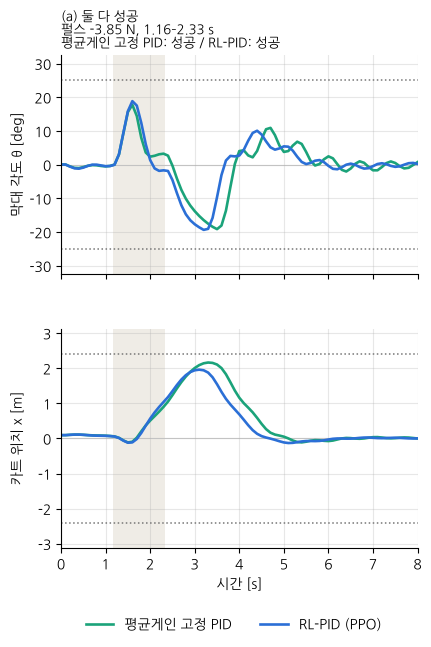


[둘 다 성공] seed 20023: 펄스 -3.85 N, 1.16–2.33 s
  평균게인 고정 PID  성공 | 최대 θ -19.1° @ 3.50 s | 최대 x +2.16 m @ 3.30 s | 외란 중 Kd 5.62~5.62
  RL-PID (PPO) 성공 | 최대 θ -19.4° @ 3.20 s | 최대 x +1.96 m @ 3.10 s | 외란 중 Kd 3.66~5.69


In [ ]:
# ============================================================
# 13. 평균게인 고정 PID vs RL-PID(PPO): 결과가 갈린 에피소드의 θ, x
# ============================================================
# 셀 12(외란 배율 DIST_SCALE, 평균 게인 MEAN_RL_GAINS, run_controller, CHECK_SEEDS)를
# 먼저 실행해야 한다.
# 확인용 에피소드에서
#   - RL-PID만 성공한 경우 (최대 2개, 시드 순)
#   - 둘 다 성공한 경우 중 막대가 가장 크게 기울어진 1개 (둘 다 버틴 가장 어려운 외란)
# 를 그린다. 평균게인 고정 PID만 성공한 경우의 개수도 함께 출력한다.
import matplotlib.pyplot as plt
import numpy as np

N_RL_ONLY = 2          # RL-PID만 성공한 사례 수

split_rl, split_mean, both_ok = [], [], []
for s_ in CHECK_SEEDS:
    lm = run_controller(s_, MEAN_RL_GAINS, scale=DIST_SCALE)
    lr = run_controller(s_, "rl", scale=DIST_SCALE)
    if lr["success"] and not lm["success"]:
        split_rl.append((s_, lm, lr))
    elif lm["success"] and not lr["success"]:
        split_mean.append((s_, lm, lr))
    elif lm["success"] and lr["success"]:
        peak = max(np.abs(lm["theta"]).max(), np.abs(lr["theta"]).max())
        both_ok.append((peak, s_, lm, lr))

print(f"확인용 에피소드 {len(CHECK_SEEDS)}개, 외란 ×{DIST_SCALE}")
print(f"  RL-PID만 성공: {len(split_rl)}개 {[c[0] for c in split_rl]}")
print(f"  평균게인 고정 PID만 성공: {len(split_mean)}개 {[c[0] for c in split_mean]}")
print(f"  둘 다 성공: {len(both_ok)}개")

cases = [("RL-PID만 성공", c) for c in split_rl[:N_RL_ONLY]]
if both_ok:
    _, s_, lm, lr = max(both_ok, key=lambda b: b[0])
    cases.append(("둘 다 성공", (s_, lm, lr)))


def describe_disturbance(cfg):
    span = f"{cfg['start_time']:.2f}–{cfg['start_time'] + cfg['duration']:.2f} s"
    if cfg["kind"] == "pulse":
        return f"펄스 {cfg['magnitude']:+.2f} N, {span}"
    if cfg["kind"] == "sine":
        return f"정현파 {cfg['amplitude']:.2f} N, {cfg['frequency']:.2f} Hz, {span}"
    if cfg["kind"] == "random":
        return f"랜덤 ±{cfg['amplitude']:.2f} N"
    return "외란 없음"


def series(lg, key, conv=lambda v: v):
    t = np.concatenate([[0.0], lg["time"]])
    y = conv(lg[key])
    return t, np.concatenate([[y[0]], y])


C_MEAN, C_RL, C_DIST = "#1BA37A", "#2B6FD6", "#EFECE6"
THETA_LIM_DEG = np.rad2deg(THETA_LIMIT)
n = len(cases)

fig, axes = plt.subplots(
    2, n, figsize=(4.6 * n, 6.4), sharex=True, squeeze=False,
    gridspec_kw=dict(hspace=0.25, wspace=0.32),
)

for col, (title, (seed, lm, lr)) in enumerate(cases):
    cfg = lr["dist_config"]
    ax_th, ax_x = axes[:, col]

    for ax in (ax_th, ax_x):
        if cfg["kind"] in ("pulse", "sine"):
            ax.axvspan(cfg["start_time"], cfg["start_time"] + cfg["duration"],
                       color=C_DIST, lw=0, zorder=0)

    for lg, c, name in ((lm, C_MEAN, "평균게인 고정 PID"), (lr, C_RL, "RL-PID (PPO)")):
        res = "성공" if lg["success"] else f"실패 {lg['elapsed_time']:.2f} s"
        t, th = series(lg, "theta", np.rad2deg)
        t, x = series(lg, "x")
        ax_th.plot(t, th, color=c, lw=1.9, label=name)
        ax_x.plot(t, x, color=c, lw=1.9)
        if not lg["success"]:
            ax_th.plot(t[-1], th[-1], "x", color=c, ms=10, mew=2.4, zorder=5)
            ax_x.plot(t[-1], x[-1], "x", color=c, ms=10, mew=2.4, zorder=5)

    for ax, lim in ((ax_th, THETA_LIM_DEG), (ax_x, X_LIMIT)):
        for sgn in (-1, 1):
            ax.axhline(sgn * lim, color="#777", ls=":", lw=1.1)
        ax.axhline(0, color="#ccc", lw=0.8, zorder=0)
        ax.set_ylim(-1.3 * lim, 1.3 * lim)
        ax.set_xlim(0, EPISODE_LENGTH)
        ax.grid(alpha=0.3)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)

    res_m = "성공" if lm["success"] else f"실패 {lm['elapsed_time']:.2f} s"
    res_r = "성공" if lr["success"] else f"실패 {lr['elapsed_time']:.2f} s"
    ax_th.set_title(f"({'abcdef'[col]}) {title}\n{describe_disturbance(cfg)}\n"
                    f"평균게인 고정 PID: {res_m} / RL-PID: {res_r}",
                    loc="left", fontsize=9.5)
    ax_x.set_xlabel("시간 [s]")
    if col == 0:
        ax_th.set_ylabel("막대 각도 θ [deg]")
        ax_x.set_ylabel("카트 위치 x [m]")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.04),
           ncol=2, fontsize=10, frameon=False)
fig.align_ylabels(axes[:, 0])
plt.savefig("mean_vs_ppo_theta_x.png", dpi=300, bbox_inches="tight")
plt.show()


# 본문 작성용 수치
def first_cross(lg, key, lim):
    v = np.abs(lg[key])
    idx = np.nonzero(v > lim)[0]
    return lg["time"][idx[0]] if len(idx) else None


for title, (seed, lm, lr) in cases:
    cfg = lr["dist_config"]
    t0, t1 = cfg["start_time"], cfg["start_time"] + cfg["duration"]
    print(f"\n[{title}] seed {seed}: {describe_disturbance(cfg)}")
    for name, lg in (("평균게인 고정 PID", lm), ("RL-PID (PPO)", lr)):
        th = np.rad2deg(lg["theta"])
        i_th = np.argmax(np.abs(th))
        i_x = np.argmax(np.abs(lg["x"]))
        dist_mask = (lg["time"] >= t0) & (lg["time"] < t1 + 0.5)
        why = "" if lg["success"] else (" (위치 한계)" if abs(lg["x"][-1]) > X_LIMIT else " (각도 한계)")
        print(f"  {name:<12} {'성공' if lg['success'] else '실패 %.2f s' % lg['elapsed_time']}{why}"
              f" | 최대 θ {th[i_th]:+.1f}° @ {lg['time'][i_th]:.2f} s"
              f" | 최대 x {lg['x'][i_x]:+.2f} m @ {lg['time'][i_x]:.2f} s"
              f" | 외란 중 Kd {lg['kd'][dist_mask].min():.2f}~{lg['kd'][dist_mask].max():.2f}")


## 14. 세 제어기 비교표

기준 게인 고정 PID, 평균 게인 고정 PID, RL-PID를 같은 30개 에피소드에서 비교합니다. **전체 RMSE**는 기존처럼 실패한 에피소드의 남은 구간을 한계값으로 채워 계산하고, **공통 성공 RMSE**는 세 제어기가 모두 성공한 에피소드만으로 계산합니다.

In [ ]:
# ============================================================
# 14. 세 제어기 비교표: 전체 RMSE + 공통 성공 에피소드 RMSE
# ============================================================
# 같은 평가 시드 30개(같은 초기 상태·외란)에서 세 제어기를 실행한다.
#  - 전체 RMSE   : 기존 방식. 실패한 에피소드의 남은 구간을 한계값(25°, 2.4 m)으로 채워 계산
#  - 공통 성공 RMSE: 세 제어기가 모두 성공한 에피소드만 사용 (채운 구간이 없음)
# 셀 12를 먼저 실행해야 한다.

CONTROLLERS = {
    "고정 PID (기준 게인)": NOMINAL_GAINS,
    "평균 게인 고정 PID": MEAN_RL_GAINS,
    "RL-PID (PPO)": "rl",
}
KIND_KO = {"none": "외란 없음", "pulse": "펄스", "sine": "정현파", "random": "랜덤"}


def compare_controllers(seeds, scale, controllers=CONTROLLERS):
    logs = {name: [run_controller(s, g, scale=scale) for s in seeds]
            for name, g in controllers.items()}
    per_ep = {name: pd.DataFrame([compute_metrics(lg) for lg in L], index=seeds)
              for name, L in logs.items()}
    common = np.all([df["성공"].to_numpy() == 1.0 for df in per_ep.values()], axis=0)

    rows = {}
    for name, df in per_ep.items():
        rows[name] = {
            "전체 각도 RMSE [deg]": df["각도 RMSE [deg]"].mean(),
            "전체 위치 RMSE [m]": df["위치 RMSE [m]"].mean(),
            "공통성공 각도 RMSE [deg]": df.loc[common, "각도 RMSE [deg]"].mean(),
            "공통성공 위치 RMSE [m]": df.loc[common, "위치 RMSE [m]"].mean(),
            "성공": f"{int(df['성공'].sum())}/{len(df)}",
            "성공률 [%]": 100 * df["성공"].mean(),
            "평균 생존시간 [s]": df["생존시간 [s]"].mean(),
        }
    return pd.DataFrame(rows).T.infer_objects(), common, logs, per_ep


table, common_mask, cmp_logs, cmp_per_ep = compare_controllers(CHECK_SEEDS, DIST_SCALE)
n_common = int(common_mask.sum())

print(f"외란 배율 ×{DIST_SCALE}, 평가 에피소드 {len(CHECK_SEEDS)}개, "
      f"세 제어기 공통 성공 에피소드 {n_common}개")
display(table.round(3))

# 기준 고정 PID 대비 감소율 [%]
base = table.loc["고정 PID (기준 게인)"]
rmse_cols = [c for c in table.columns if "RMSE" in c]
improve = pd.DataFrame({
    name: {c: 100 * (1 - table.loc[name, c] / base[c]) for c in rmse_cols}
    for name in table.index if name != "고정 PID (기준 게인)"
}).T
print("\n기준 고정 PID 대비 RMSE 감소율 [%]")
display(improve.round(1))

# 공통 성공에서 빠진 에피소드: 어느 제어기가 실패했는지
kinds = [cmp_logs["RL-PID (PPO)"][i]["dist_config"]["kind"] for i in range(len(CHECK_SEEDS))]
print("\n평가 30개 외란 구성:", pd.Series([KIND_KO[k] for k in kinds]).value_counts().to_dict())
print("공통 성공에서 빠진 에피소드:")
for i, s in enumerate(CHECK_SEEDS):
    if common_mask[i]:
        continue
    failed = [n for n in CONTROLLERS if not cmp_logs[n][i]["success"]]
    print(f"  seed {s} ({KIND_KO[kinds[i]]}): 실패 = {', '.join(failed)}")

table.to_csv(f"compare_table_x{DIST_SCALE}.csv", encoding="utf-8-sig")
pd.concat(cmp_per_ep, axis=1).to_csv(f"compare_per_episode_x{DIST_SCALE}.csv", encoding="utf-8-sig")


외란 배율 ×1.0, 평가 에피소드 30개, 세 제어기 공통 성공 에피소드 27개


,전체 각도 RMSE [deg],전체 위치 RMSE [m],공통성공 각도 RMSE [deg],공통성공 위치 RMSE [m],성공,성공률 [%],평균 생존시간 [s]
고정 PID (기준 게인),4.409,0.305,2.541,0.118,27/30,90.0,7.46
평균 게인 고정 PID,2.094,0.137,1.743,0.112,30/30,100.0,8.00
RL-PID (PPO),2.114,0.134,1.766,0.113,30/30,100.0,8.00



기준 고정 PID 대비 RMSE 감소율 [%]


,전체 각도 RMSE [deg],전체 위치 RMSE [m],공통성공 각도 RMSE [deg],공통성공 위치 RMSE [m]
평균 게인 고정 PID,52.5,55.0,31.4,5.1
RL-PID (PPO),52.0,56.0,30.5,4.4



평가 30개 외란 구성: {'펄스': 12, '정현파': 9, '외란 없음': 6, '랜덤': 3}
공통 성공에서 빠진 에피소드:
  seed 20019 (정현파): 실패 = 고정 PID (기준 게인)
  seed 20023 (펄스): 실패 = 고정 PID (기준 게인)
  seed 20026 (정현파): 실패 = 고정 PID (기준 게인)


## 15. 외란 배율에 따른 비교

외란 크기를 1.0~2.0배로 키우며 세 제어기의 성공 횟수와 RMSE가 어떻게 달라지는지 확인합니다. 배율마다 평균 게인은 별도 시드에서 다시 구합니다.

In [ ]:
# ============================================================
# 15. 외란 배율에 따른 비교 (고정 PID의 한계가 드러나는 외란 크기 확인)
# ============================================================
# 배율마다 평균 게인을 별도 시드(GAIN_SEEDS)에서 다시 구한 뒤, 평가 시드 30개로 비교한다.
SCALES = [1.0, 1.25, 1.5, 1.75, 2.0]
NAMES = list(CONTROLLERS)
SHORT = {"고정 PID (기준 게인)": "기준", "평균 게인 고정 PID": "평균", "RL-PID (PPO)": "RL"}

sweep_rows = []
for sc in SCALES:
    g_mean = mean_rl_gains(GAIN_SEEDS, sc)
    ctrls = {NAMES[0]: NOMINAL_GAINS, NAMES[1]: g_mean, NAMES[2]: "rl"}
    tb, cm, _, _ = compare_controllers(CHECK_SEEDS, sc, ctrls)
    row = {"배율": sc, "평균 Kp": g_mean[0], "평균 Kd": g_mean[2], "공통성공": int(cm.sum())}
    for n in NAMES:
        row[f"성공_{SHORT[n]}"] = tb.loc[n, "성공"]
    for n in NAMES:
        row[f"전체θ_{SHORT[n]}"] = tb.loc[n, "전체 각도 RMSE [deg]"]
    for n in NAMES:
        row[f"공통θ_{SHORT[n]}"] = tb.loc[n, "공통성공 각도 RMSE [deg]"]
    for n in NAMES:
        row[f"공통x_{SHORT[n]}"] = tb.loc[n, "공통성공 위치 RMSE [m]"]
    sweep_rows.append(row)

sweep = pd.DataFrame(sweep_rows).set_index("배율")
display(sweep.round(3))
sweep.to_csv("scale_sweep.csv", encoding="utf-8-sig")


,평균 Kp,평균 Kd,공통성공,성공_기준,성공_평균,성공_RL,전체θ_기준,전체θ_평균,전체θ_RL,공통θ_기준,공통θ_평균,공통θ_RL,공통x_기준,공통x_평균,공통x_RL
배율,,,,,,,,,,,,,,,
1.00,19.448,5.624,27,27/30,30/30,30/30,4.409,2.094,2.114,2.541,1.743,1.766,0.118,0.112,0.113
1.25,19.455,5.628,27,27/30,29/30,29/30,4.986,2.979,2.988,3.087,2.131,2.132,0.155,0.139,0.140
1.50,19.467,5.634,26,26/30,29/30,29/30,5.970,3.508,3.502,3.464,2.398,2.382,0.177,0.156,0.154
1.75,19.467,5.646,24,24/30,28/30,27/30,7.226,4.436,4.864,3.666,2.492,2.484,0.206,0.170,0.171
2.00,19.474,5.649,22,22/30,25/30,23/30,8.333,6.146,6.967,3.637,2.456,2.484,0.182,0.148,0.155
